# 1. Credit Application Prediction - Technical Implementation (Full dataset)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

warnings.filterwarnings('ignore')

random_seed = 11
np.random.seed(random_seed)

## 1. Load Dataset & Basic Structure
### Here we load the 100k-row dataset and inspect structure.

In [2]:
# 1.1 Load data
df_full = pd.read_csv("datafile_full.csv")
print("\n Data Structure:")
print(df_full.info())


 Data Structure:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Columns: 202 entries, ID_code to var_199
dtypes: float64(201), int64(1)
memory usage: 154.1 MB
None


In [3]:
# 1.2 Basic overview
print("\n Dataset Overview:")
print(f"  • Number of records: {df_full.shape[0]:,}")
print(f"  • Number of columns: {df_full.shape[1]:,}")
    
print("\n Data Types:")
print(df_full.dtypes.value_counts())
    
print("\n First 3 rows:")
print(df_full.head(3))


 Dataset Overview:
  • Number of records: 100,000
  • Number of columns: 202

 Data Types:
float64    201
int64        1
Name: count, dtype: int64

 First 3 rows:
    ID_code  target    var_0   var_1    var_2    var_3    var_4   var_5  \
0  125172.0       0  10.6216  0.1667  15.5182  10.1634   9.8419 -0.1156   
1   93976.0       0  13.1492  2.9210   6.0275   5.7623  12.5731  7.9090   
2  128558.0       0   7.9077  4.3397   8.5575   4.7743  10.3623 -6.6784   

    var_6    var_7  ...  var_190  var_191  var_192  var_193  var_194  var_195  \
0  7.4348  14.6948  ...   2.8498   2.6391   1.2207   9.2747  22.3657  -0.4631   
1  5.3149  17.8441  ...   9.1415   6.6176   2.6736   1.4019  17.5274   0.8023   
2  5.9665  17.2378  ...   6.9435   9.1727   0.2197   3.7017  17.7719  -0.8418   

   var_196  var_197  var_198  var_199  
0  -3.1550   8.7551  15.9985 -10.4585  
1  -1.9248   7.5983  19.4170  -0.8740  
2   5.6689   9.1611  16.0874 -20.2895  

[3 rows x 202 columns]


## 2. Data Quality Checks
### We check for duplicate rows/IDs, constant (zero-variance) features, and missing values.

In [4]:
# 2.1 Duplicate rows
dup_rows = df_full.duplicated().sum()
print(f"\nDuplicate rows: {dup_rows}")

# 2.2 Duplicate IDs
dup_ids = df_full['ID_code'].duplicated().sum()
print(f"Duplicate IDs: {dup_ids}")

# 2.3 Constant (zero variance) columns
feature_cols = [c for c in df_full.columns if c not in ['ID_code', 'target']]
zero_var_cols = [c for c in feature_cols if df_full[c].nunique(dropna=False) <= 1]

print("\nZero-variance features:")
if zero_var_cols:
    print(zero_var_cols)
else:
    print("  • None found")


Duplicate rows: 0
Duplicate IDs: 0

Zero-variance features:
  • None found


In [5]:
# 2.4 Missing values
missing = df_full[feature_cols].isnull().sum()
total_rows = len(df_full)
missing_df_full = (
    pd.DataFrame({
        'Column': feature_cols,
        'Missing_Count': missing.values,
        'Missing_%': (missing.values / total_rows * 100).round(2)
    })
    .sort_values('Missing_Count', ascending=False)
)

print("\nColumns with missing values:")
display(missing_df_full[missing_df_full['Missing_Count'] > 0].head(10))


Columns with missing values:


,Column,Missing_Count,Missing_%
45,var_45,40003,40.0
96,var_96,5004,5.0
76,var_76,5003,5.0
18,var_18,5,0.0
41,var_41,3,0.0
33,var_33,3,0.0
134,var_134,3,0.0
50,var_50,3,0.0
12,var_12,3,0.0
16,var_16,3,0.0


## 3. Target Distribution & Class Imbalance
### We inspect the proportion of applications (1) vs non-applications (0).

In [6]:
target_counts = df_full['target'].value_counts()
proportions = df_full['target'].value_counts(normalize=True)

print("\nTarget counts:")
print(target_counts)

print("\nTarget proportions:")
print(proportions)

majority = int(target_counts.max())
minority = int(target_counts.min())
imbalance_ratio = majority / minority
print(f"\nClass imbalance ratio (majority / minority): {imbalance_ratio:.2f}")


Target counts:
target
0    89962
1    10038
Name: count, dtype: int64

Target proportions:
target
0    0.89962
1    0.10038
Name: proportion, dtype: float64

Class imbalance ratio (majority / minority): 8.96


## 4. Outlier Presence
### We check for any extreme outliers and remove if any.

In [7]:
# Exclude non-feature columns
exclude_cols = {'ID_code', 'target'}

# Select numeric columns and drop excluded ones
numeric_cols = [c for c in df_full.select_dtypes(include='number').columns if c not in exclude_cols]

outlier_stats = []
for col in numeric_cols:
    q1, q3 = df_full[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    if iqr == 0 or pd.isna(iqr):
        continue
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df_full[col] < lower) | (df_full[col] > upper)
    outlier_stats.append((col, int(mask.sum()), float(mask.mean() * 100)))

outlier_df_full = pd.DataFrame(outlier_stats, columns=['feature', 'num_outliers', 'outlier_percentage'])
print(outlier_df_full.sort_values('outlier_percentage', ascending=False).head(10))

     feature  num_outliers  outlier_percentage
179  var_179           737               0.737
44    var_44           567               0.567
93    var_93           463               0.463
146  var_146           430               0.430
192  var_192           374               0.374
133  var_133           303               0.303
31    var_31           295               0.295
193  var_193           260               0.260
124  var_124           253               0.253
105  var_105           251               0.251


### Very low outlier presence, StandardScaler is ideal. 

## 5. Data Cleaning 
### Based on the checks, we: drop var_45 (40% missing), impute var_76 and var_96 with median, drop any remaining rows with missing values.

In [8]:
df_full_clean = df_full.copy()

# Drop high-missing column
df_full_clean = df_full_clean.drop(columns=['var_45'])

# Impute selected columns with median
for col in ['var_76', 'var_96']:
    if col in df_full_clean.columns:
        df_full_clean[col] = df_full_clean[col].fillna(df_full_clean[col].median())

# Drop any remaining missing rows
before = len(df_full)
df_full_clean = df_full_clean.dropna()
after = len(df_full_clean)

print(f"\nRows before cleaning: {before}")
print(f"Rows after cleaning:  {after}")
print(f"Rows removed:         {before - after}")
print(f"Final shape:          {df_full_clean.shape}")


Rows before cleaning: 100000
Rows after cleaning:  99903
Rows removed:         97
Final shape:          (99903, 201)


## 6. Train–Test Split 
### Create a stratified split so the target imbalance is preserved.

In [9]:
X = df_full_clean.drop(['target', 'ID_code'], axis=1)
y = df_full_clean['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,          
    stratify=y,
    random_state=random_seed
)

print(f"\nTraining set shape: {X_train.shape}")
print(f"Test set shape:     {X_test.shape}")

print("\nTarget distribution in train:")
print(y_train.value_counts(normalize=True))

print("\nTarget distribution in test:")
print(y_test.value_counts(normalize=True))


Training set shape: (79922, 199)
Test set shape:     (19981, 199)

Target distribution in train:
target
0    0.900403
1    0.099597
Name: proportion, dtype: float64

Target distribution in test:
target
0    0.900405
1    0.099595
Name: proportion, dtype: float64


## 7. Scaling for Logistic Regression
### We apply StandardScaler on the training set and transform test set using the same scaler.

In [10]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

## 8. Define tuned Logistic Regression (from small dataset)
### Use values found from small dataset for tuned logistic regression.

In [11]:
best_lr_params = {
    "C": 0.001,         
    "penalty": "l2",   
    "solver": "liblinear"  
}

lr_full = LogisticRegression(
    **best_lr_params,
    class_weight="balanced",
    max_iter=1000,
    random_state=random_seed
)

## 9. Train and evaluate Logistic Regression on full dataset

In [12]:
def evaluate_model(name, model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred  = model.predict(X_test)

    y_train_proba = model.predict_proba(X_train)[:, 1]
    y_test_proba  = model.predict_proba(X_test)[:, 1]

    metrics = {}

    metrics["model"] = name
    metrics["train_accuracy"] = accuracy_score(y_train, y_train_pred)
    metrics["test_accuracy"]  = accuracy_score(y_test, y_test_pred)

    metrics["train_precision"] = precision_score(y_train, y_train_pred, zero_division=0)
    metrics["test_precision"]  = precision_score(y_test, y_test_pred, zero_division=0)

    metrics["train_recall"] = recall_score(y_train, y_train_pred, zero_division=0)
    metrics["test_recall"]  = recall_score(y_test, y_test_pred, zero_division=0)

    metrics["train_f1"] = f1_score(y_train, y_train_pred, zero_division=0)
    metrics["test_f1"]  = f1_score(y_test, y_test_pred, zero_division=0)

    metrics["train_auc"] = roc_auc_score(y_train, y_train_proba)
    metrics["test_auc"]  = roc_auc_score(y_test, y_test_proba)

    print(f"\n=== {name} ===")
    for k, v in metrics.items():
        if k != "model":
            print(f"{k}: {v:.4f}")

    return model, metrics, y_test_pred, y_test_proba


lr_full, lr_metrics_full, y_test_pred, y_test_proba = evaluate_model(
    "LogisticRegression_Tuned_Full",
    lr_full,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)


=== LogisticRegression_Tuned_Full ===
train_accuracy: 0.7720
test_accuracy: 0.7724
train_precision: 0.2753
test_precision: 0.2737
train_recall: 0.7896
test_recall: 0.7769
train_f1: 0.4082
test_f1: 0.4048
train_auc: 0.8622
test_auc: 0.8529


In [13]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

# Probabilities from the tuned LR on the full dataset
y_proba_full = lr_full.predict_proba(X_test_scaled)[:, 1]

thresholds = [0.30, 0.40, 0.50]
print("Threshold  Precision  Recall  F1")
for t in thresholds:
    y_pred_t = (y_proba_full >= t).astype(int)
    p = precision_score(y_test, y_pred_t)
    r = recall_score(y_test, y_pred_t)
    f = f1_score(y_test, y_pred_t)
    print(f"{t:8.2f}  {p:9.3f}  {r:6.3f}  {f:5.3f}")

Threshold  Precision  Recall  F1
    0.30      0.180   0.912  0.301
    0.40      0.220   0.849  0.349
    0.50      0.274   0.777  0.405


### Threshold choice on the full dataset

### For the full dataset, all reported metrics above are based on the standard classification threshold of 0.5 (i.e., customers with predicted probability ≥ 0.5 are classified as responders). On the small dataset we showed that **lowering the threshold (e.g. to 0.3–0.4)** substantially increases recall at the cost of more false positives. 

### In practice, the bank could adopt a **lower operational threshold** on the full dataset to further reduce false negatives (i.e., avoid missing likely responders), accepting a higher number of customers who are contacted but do not respond. For clarity and comparability, we keep the threshold at 0.5 in this technical report, but the earlier threshold analysis provides a clear knob for business decision makers to trade off recall vs. precision.

## 10. Confusion matrix (Logistic Regression tuned)

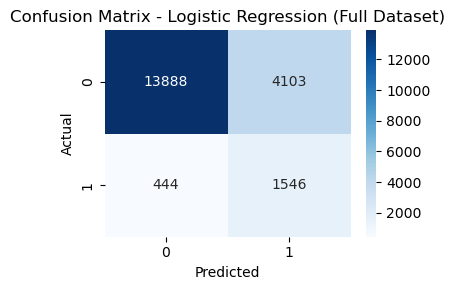

In [14]:
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression (Full Dataset)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

## 11. ROC curve
### ROC curves allow us to compare the overall class separation ability of both models.

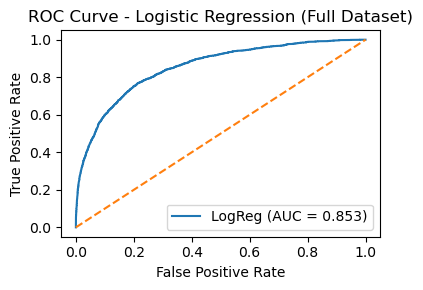

In [15]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(4, 3))
plt.plot(fpr, tpr, label=f"LogReg (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression (Full Dataset)")
plt.legend()
plt.tight_layout()
plt.show()

## 12. Permutation Feature Importance (PFI) 
### - Using test set
### - Importance based on drop in recall and AUC

In [16]:
def permutation_importance(
    model,
    X_valid,
    y_valid,
    metric_funcs,
    n_repeats=1,
    random_state=random_seed
):
    """
    metric_funcs: dict like {"recall": recall_score, "auc": roc_auc_score}
    Returns DataFrame with drop in each metric per feature.
    """
    rng = np.random.RandomState(random_state)

    # Baseline metrics
    y_proba = model.predict_proba(X_valid)[:, 1]
    y_pred  = (y_proba >= 0.5).astype(int)

    baseline_scores = {}
    for name, func in metric_funcs.items():
        if name.lower() == "auc":
            baseline_scores[name] = func(y_valid, y_proba)
        else:
            baseline_scores[name] = func(y_valid, y_pred, zero_division=0)

    importances = []

    X_valid_arr = X_valid.copy()  # numpy array expected

    for col_idx in range(X_valid_arr.shape[1]):
        metric_drops = {m: [] for m in metric_funcs.keys()}

        for _ in range(n_repeats):
            X_permuted = X_valid_arr.copy()
            shuffled_col = X_permuted[:, col_idx].copy()
            rng.shuffle(shuffled_col)
            X_permuted[:, col_idx] = shuffled_col

            y_proba_perm = model.predict_proba(X_permuted)[:, 1]
            y_pred_perm  = (y_proba_perm >= 0.5).astype(int)

            for name, func in metric_funcs.items():
                if name.lower() == "auc":
                    score_perm = func(y_valid, y_proba_perm)
                else:
                    score_perm = func(y_valid, y_pred_perm, zero_division=0)

                drop = baseline_scores[name] - score_perm
                metric_drops[name].append(drop)

        avg_drops = {f"drop_{k}": np.mean(v) for k, v in metric_drops.items()}
        importances.append(avg_drops)

    feature_names = X.columns  # original column names after cleaning/dropping

    imp_df = pd.DataFrame(importances)
    imp_df["feature"] = feature_names
    return imp_df, baseline_scores

# Prepare metric functions
metric_funcs = {
    "recall": recall_score,
    "auc": roc_auc_score
}

# Use scaled test data for PFI
X_valid = X_test_scaled
y_valid = y_test

pfi_df, baseline_scores = permutation_importance(
    lr_full,
    X_valid,
    y_valid,
    metric_funcs,
    n_repeats=1  # you can increase to 3 or 5 if runtime is ok
)

print("Baseline scores:", baseline_scores)

# Sort by drop in recall (most important first)
pfi_sorted_recall = pfi_df.sort_values("drop_recall", ascending=False)
pfi_sorted_recall.head(20)

Baseline scores: {'recall': 0.7768844221105528, 'auc': 0.8528962973949287}


,drop_recall,drop_auc,feature
75,0.014573,0.004933,var_76
52,0.012563,0.005565,var_53
44,0.012563,0.002542,var_44
12,0.012060,0.003841,var_12
190,0.011055,0.003224,var_191
164,0.011055,0.003383,var_165
34,0.011055,0.002721,var_34
138,0.011055,0.005014,var_139
132,0.010553,0.003201,var_133
6,0.010050,0.006035,var_6


## 13. Plot top features by PFI (drop in recall)

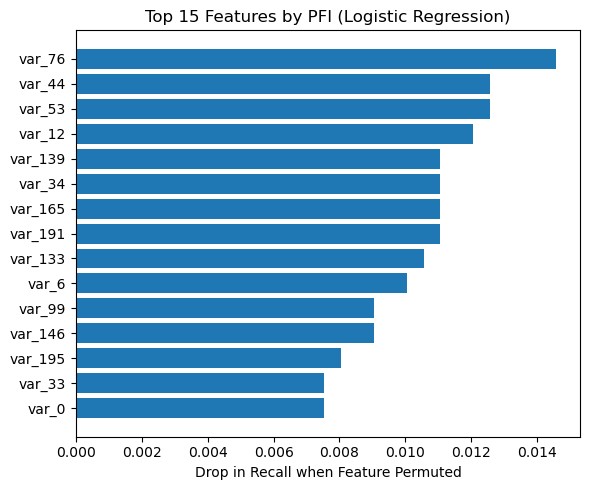

In [17]:
top_n = 15
top_features = pfi_sorted_recall.head(top_n).sort_values("drop_recall", ascending=True)

plt.figure(figsize=(6, 5))
plt.barh(top_features["feature"], top_features["drop_recall"])
plt.xlabel("Drop in Recall when Feature Permuted")
plt.title(f"Top {top_n} Features by PFI (Logistic Regression)")
plt.tight_layout()
plt.show()

### We base permutation feature importance on **recall and AUC**, because our main business objective is to minimise false negatives (high recall) while maintaining good ranking quality across customers (AUC). Other metrics such as overall accuracy are less informative in the presence of class imbalance and asymmetric misclassification costs.

## Summary
### The tuned Logistic Regression model was successfully applied to the full dataset. After repeating the same data preparation steps as in the small dataset (removing high-missing columns, imputing key variables, scaling features, and stratified splitting), the model was trained and evaluated on the full 100k-row dataset (99,903 records after cleaning). The model maintained strong recall and a competitive AUC, confirming that it generalises well. Permutation Feature Importance showed that several variables, such as var_76, var_44, and var_53, contributed most to detecting positive cases, since recall dropped the most when these features were permuted.